In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
from pathlib import Path
import plotly.express as px
import numpy as np

pd.options.mode.chained_assignment = None


In [20]:
# Resolve output folder relative to repository so the notebook is portable
repo_root = Path.cwd().parent if Path.cwd().name == "plots" else Path.cwd()
OUTPUT_DIR = repo_root / "industry" / "output_data"

# Prefer canonical wide output; fallback to any matching wide file
csv_candidates = sorted(OUTPUT_DIR.glob("final_energy_demand_detailed_sectors_wide_*.csv"))
if not csv_candidates:
    csv_candidates = sorted(OUTPUT_DIR.glob("industry_*.csv"))

if not csv_candidates:
    raise FileNotFoundError(
        f"No industry output CSV found in {OUTPUT_DIR}. "
        "Expected final_energy_demand_detailed_sectors_wide_*.csv or industry_*.csv"
    )

# Avoid loading auto-generated duplicates if a canonical file exists
preferred = [p for p in csv_candidates if ".generated" not in p.name]
csv_candidates = preferred if preferred else csv_candidates

dfs = []
for csv_file in csv_candidates:
    df_tmp = pd.read_csv(
        csv_file,
        dtype={"country": str, "scenario": str, "carrier": str},
        keep_default_na=False,
        na_values=[""],
    )
    dfs.append(df_tmp)

df = pd.concat(dfs, ignore_index=True)

# Rename carriers to match plotting convention
df["carrier"] = df["carrier"].replace("oil", "liq. hydrocarbons")
# Drop carriers not used in final energy plotting
df = df[~df["carrier"].isin(["heat", "process emissions", "low-temperature heat"])]

# Fill NaN only in numeric columns to avoid converting string columns to mixed type
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(0)

# Safe unique values for display (avoid sorting mixed str/NaN(float))
countries = sorted(df["country"].dropna().astype(str).unique())

print(f"Loaded {len(dfs)} file(s) from {OUTPUT_DIR}")
print("Files     :", [p.name for p in csv_candidates])
print(f"Rows      : {len(df):,}")
print(f"Countries : {countries}")
print(f"Scenarios : {sorted(df['scenario'].unique())}")
print(f"Years     : {sorted(df['year'].unique())}")
print(f"Carriers  : {sorted(df['carrier'].unique())}")

Loaded 1 file(s) from c:\Users\eduque\Documents\models\sectoral-energy-demands\industry\output_data
Files     : ['final_energy_demand_detailed_sectors_wide_v0.2.csv']
Rows      : 488
Countries : ['Egypt', 'Morocco', 'Namibia', 'South Africa']
Scenarios : ['BAU', 'Optimistic', 'Progressive']
Years     : [np.int64(2030), np.int64(2035), np.int64(2040), np.int64(2045), np.int64(2050)]
Carriers  : ['ammonia', 'biomass', 'coal', 'electricity', 'gas', 'hydrogen', 'liq. hydrocarbons', 'methanol', 'steel']


In [5]:
df

,country,scenario,year,carrier,chemical and petrochemical,iron and steel,non-metallic minerals,paper pulp and print,machinery,construction,non-ferrous metals,transport equipment,food and tobacco,mining and quarrying,textile and leather,wood and wood products,other
0,Egypt,BAU,2030,ammonia,3.075578e+06,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
1,Egypt,BAU,2030,biomass,0.000000e+00,0.000000e+00,0.04,0.000000e+00,0.000000e+00,7.478790e+06,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,6.636419e+06
2,Egypt,BAU,2030,coal,2.475605e+05,7.687091e+06,0.02,0.000000e+00,2.185251e+06,1.509290e+07,0.000000e+00,31125.816417,2.194144e+06,5.132368e+04,9.316266e+05,26227.080177,0.000000e+00
3,Egypt,BAU,2030,electricity,1.447743e+07,2.317939e+07,0.12,0.000000e+00,2.913668e+06,4.343315e+07,2.814294e+06,41501.088557,2.925525e+06,6.843158e+04,1.242169e+06,34969.440236,3.854107e+07
4,Egypt,BAU,2030,gas,6.078465e+07,1.385483e+07,0.04,2.218448e+06,3.642085e+06,6.537918e+07,4.957035e+05,51876.360696,3.656907e+06,8.553947e+04,1.552711e+06,43711.800296,4.422487e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
483,South Africa,Progressive,2050,gas,7.353268e+06,1.531915e+05,0.10,1.000000e-01,1.122789e+05,1.114880e+07,1.462806e+06,513435.733197,1.764889e+07,0.000000e+00,5.749257e+03,0.000000,5.212406e+05
484,South Africa,Progressive,2050,hydrogen,9.700300e+05,1.424860e+07,0.15,2.561871e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
485,South Africa,Progressive,2050,methanol,4.360903e+06,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
486,South Africa,Progressive,2050,liq. hydrocarbons,0.000000e+00,5.361702e+05,0.20,1.200000e-01,2.985011e+04,1.016632e+07,5.724022e+05,168048.866756,1.921248e+07,1.046967e+07,9.729513e+03,236039.053215,1.050360e+06


In [21]:
# =============================================================
# FILTERS — set to None to include all, or provide a list
# =============================================================
SELECTED_COUNTRIES = None          # e.g. ["MA", "EG"] or None for all
SELECTED_SCENARIOS = ["BAU", "Progressive", "Optimistic"]  # exclude Historic baseline
SELECTED_YEARS     = [2035, 2040, 2050]  # e.g. [2030, 2050] or None for all years


In [22]:
# Apply filters
df_filtered = df.copy()
if SELECTED_COUNTRIES:
    df_filtered = df_filtered[df_filtered["country"].isin(SELECTED_COUNTRIES)]
if SELECTED_SCENARIOS:
    df_filtered = df_filtered[df_filtered["scenario"].isin(SELECTED_SCENARIOS)]
if SELECTED_YEARS:
    df_filtered = df_filtered[df_filtered["year"].isin(SELECTED_YEARS)]

# Melt to long format — include year in id_vars
df_long = df_filtered.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry",
    value_name="value"
)

# Industries to aggregate into "all_others"
agg_col = [
    "construction",
    "food and tobacco",
    "machinery",
    "textile and leather",
    "transport equipment",
    "wood and wood products",
    "other",
]

# Aggregate minor industries
all_others_df = df_long[df_long["industry"].isin(agg_col)].groupby(
    ["country", "scenario", "year", "carrier"]
)["value"].sum().reset_index()
all_others_df["industry"] = "all_others"

# Build aggregated long dataframe
df_long_agg = pd.concat([
    df_long[~df_long["industry"].isin(agg_col)],
    all_others_df
], ignore_index=True)

df_long_agg["value"] = df_long_agg["value"] / 1_000_000  # MWh -> TWh

# Convenience: combined scenario_year label for x-axes
df_long_agg["scenario_year"] = df_long_agg["scenario"] + "_" + df_long_agg["year"].astype(str)

print(f"df_long_agg: {len(df_long_agg):,} rows")
print(f"Industries  : {sorted(df_long_agg['industry'].unique())}")
print(f"scenario_year labels: {sorted(df_long_agg['scenario_year'].unique())}")

df_long_agg: 2,051 rows
Industries  : ['all_others', 'chemical and petrochemical', 'iron and steel', 'mining and quarrying', 'non-ferrous metals', 'non-metallic minerals', 'paper pulp and print']
scenario_year labels: ['BAU_2035', 'BAU_2040', 'BAU_2050', 'Optimistic_2035', 'Optimistic_2040', 'Optimistic_2050', 'Progressive_2035', 'Progressive_2040', 'Progressive_2050']


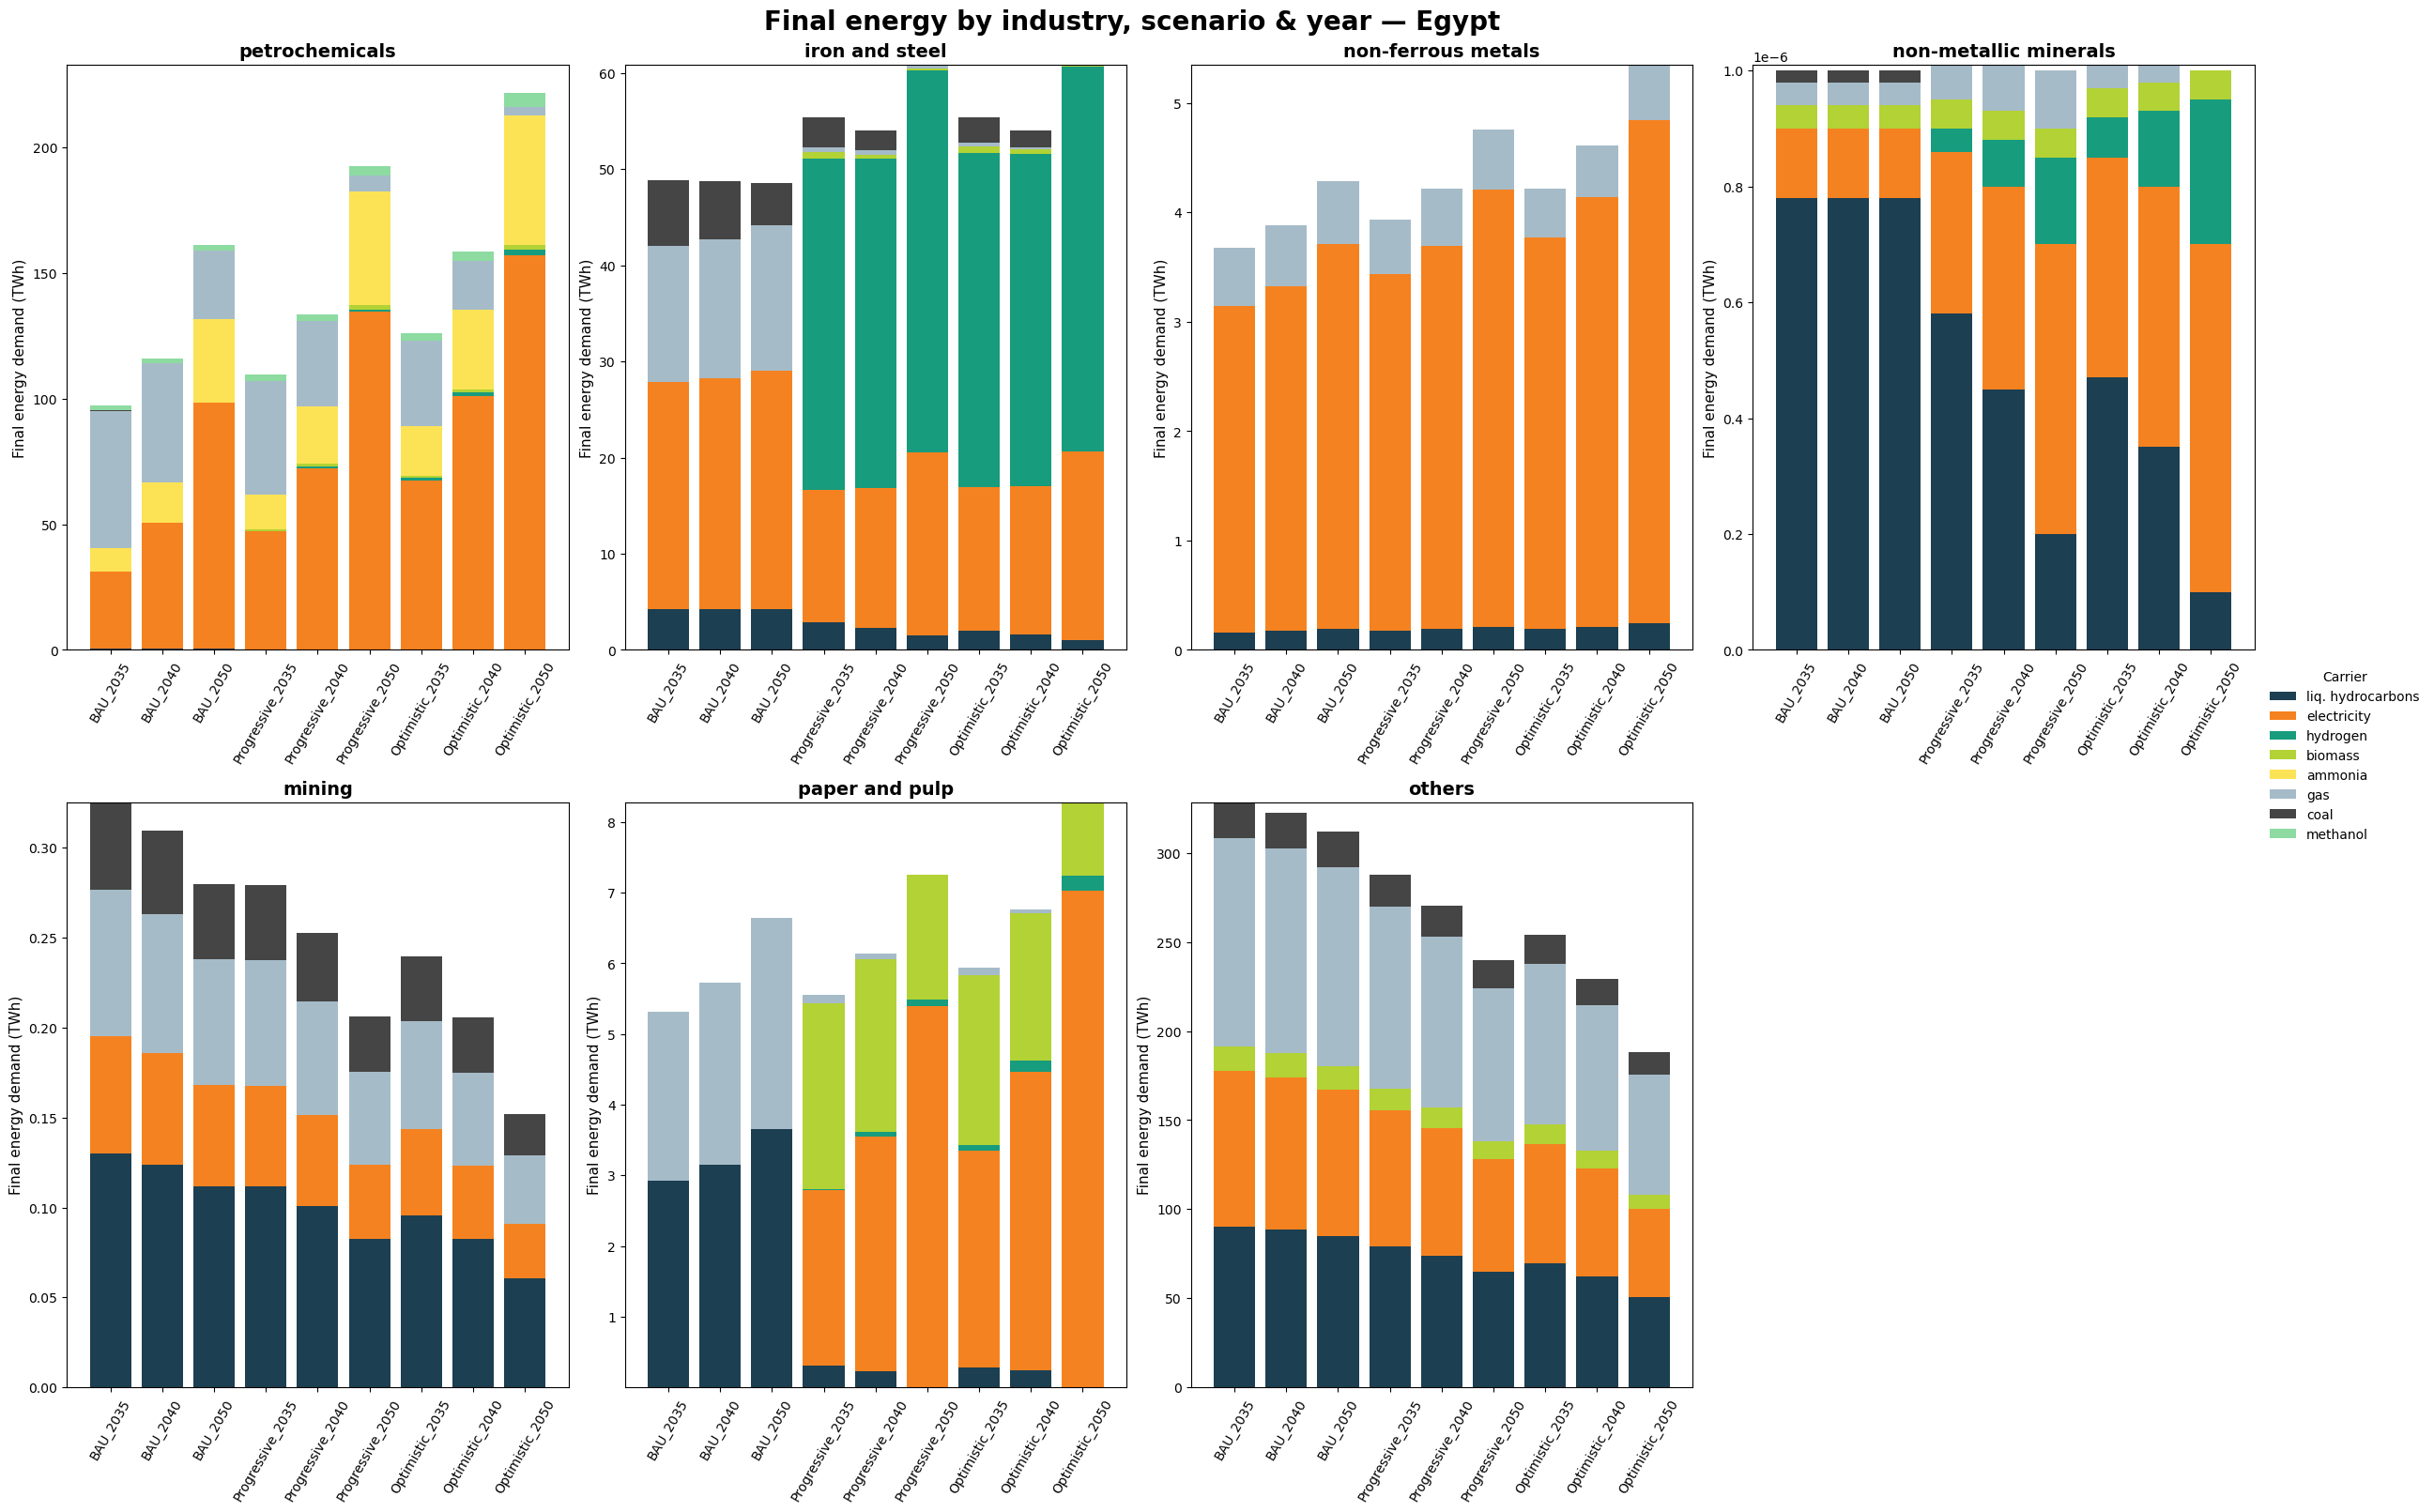

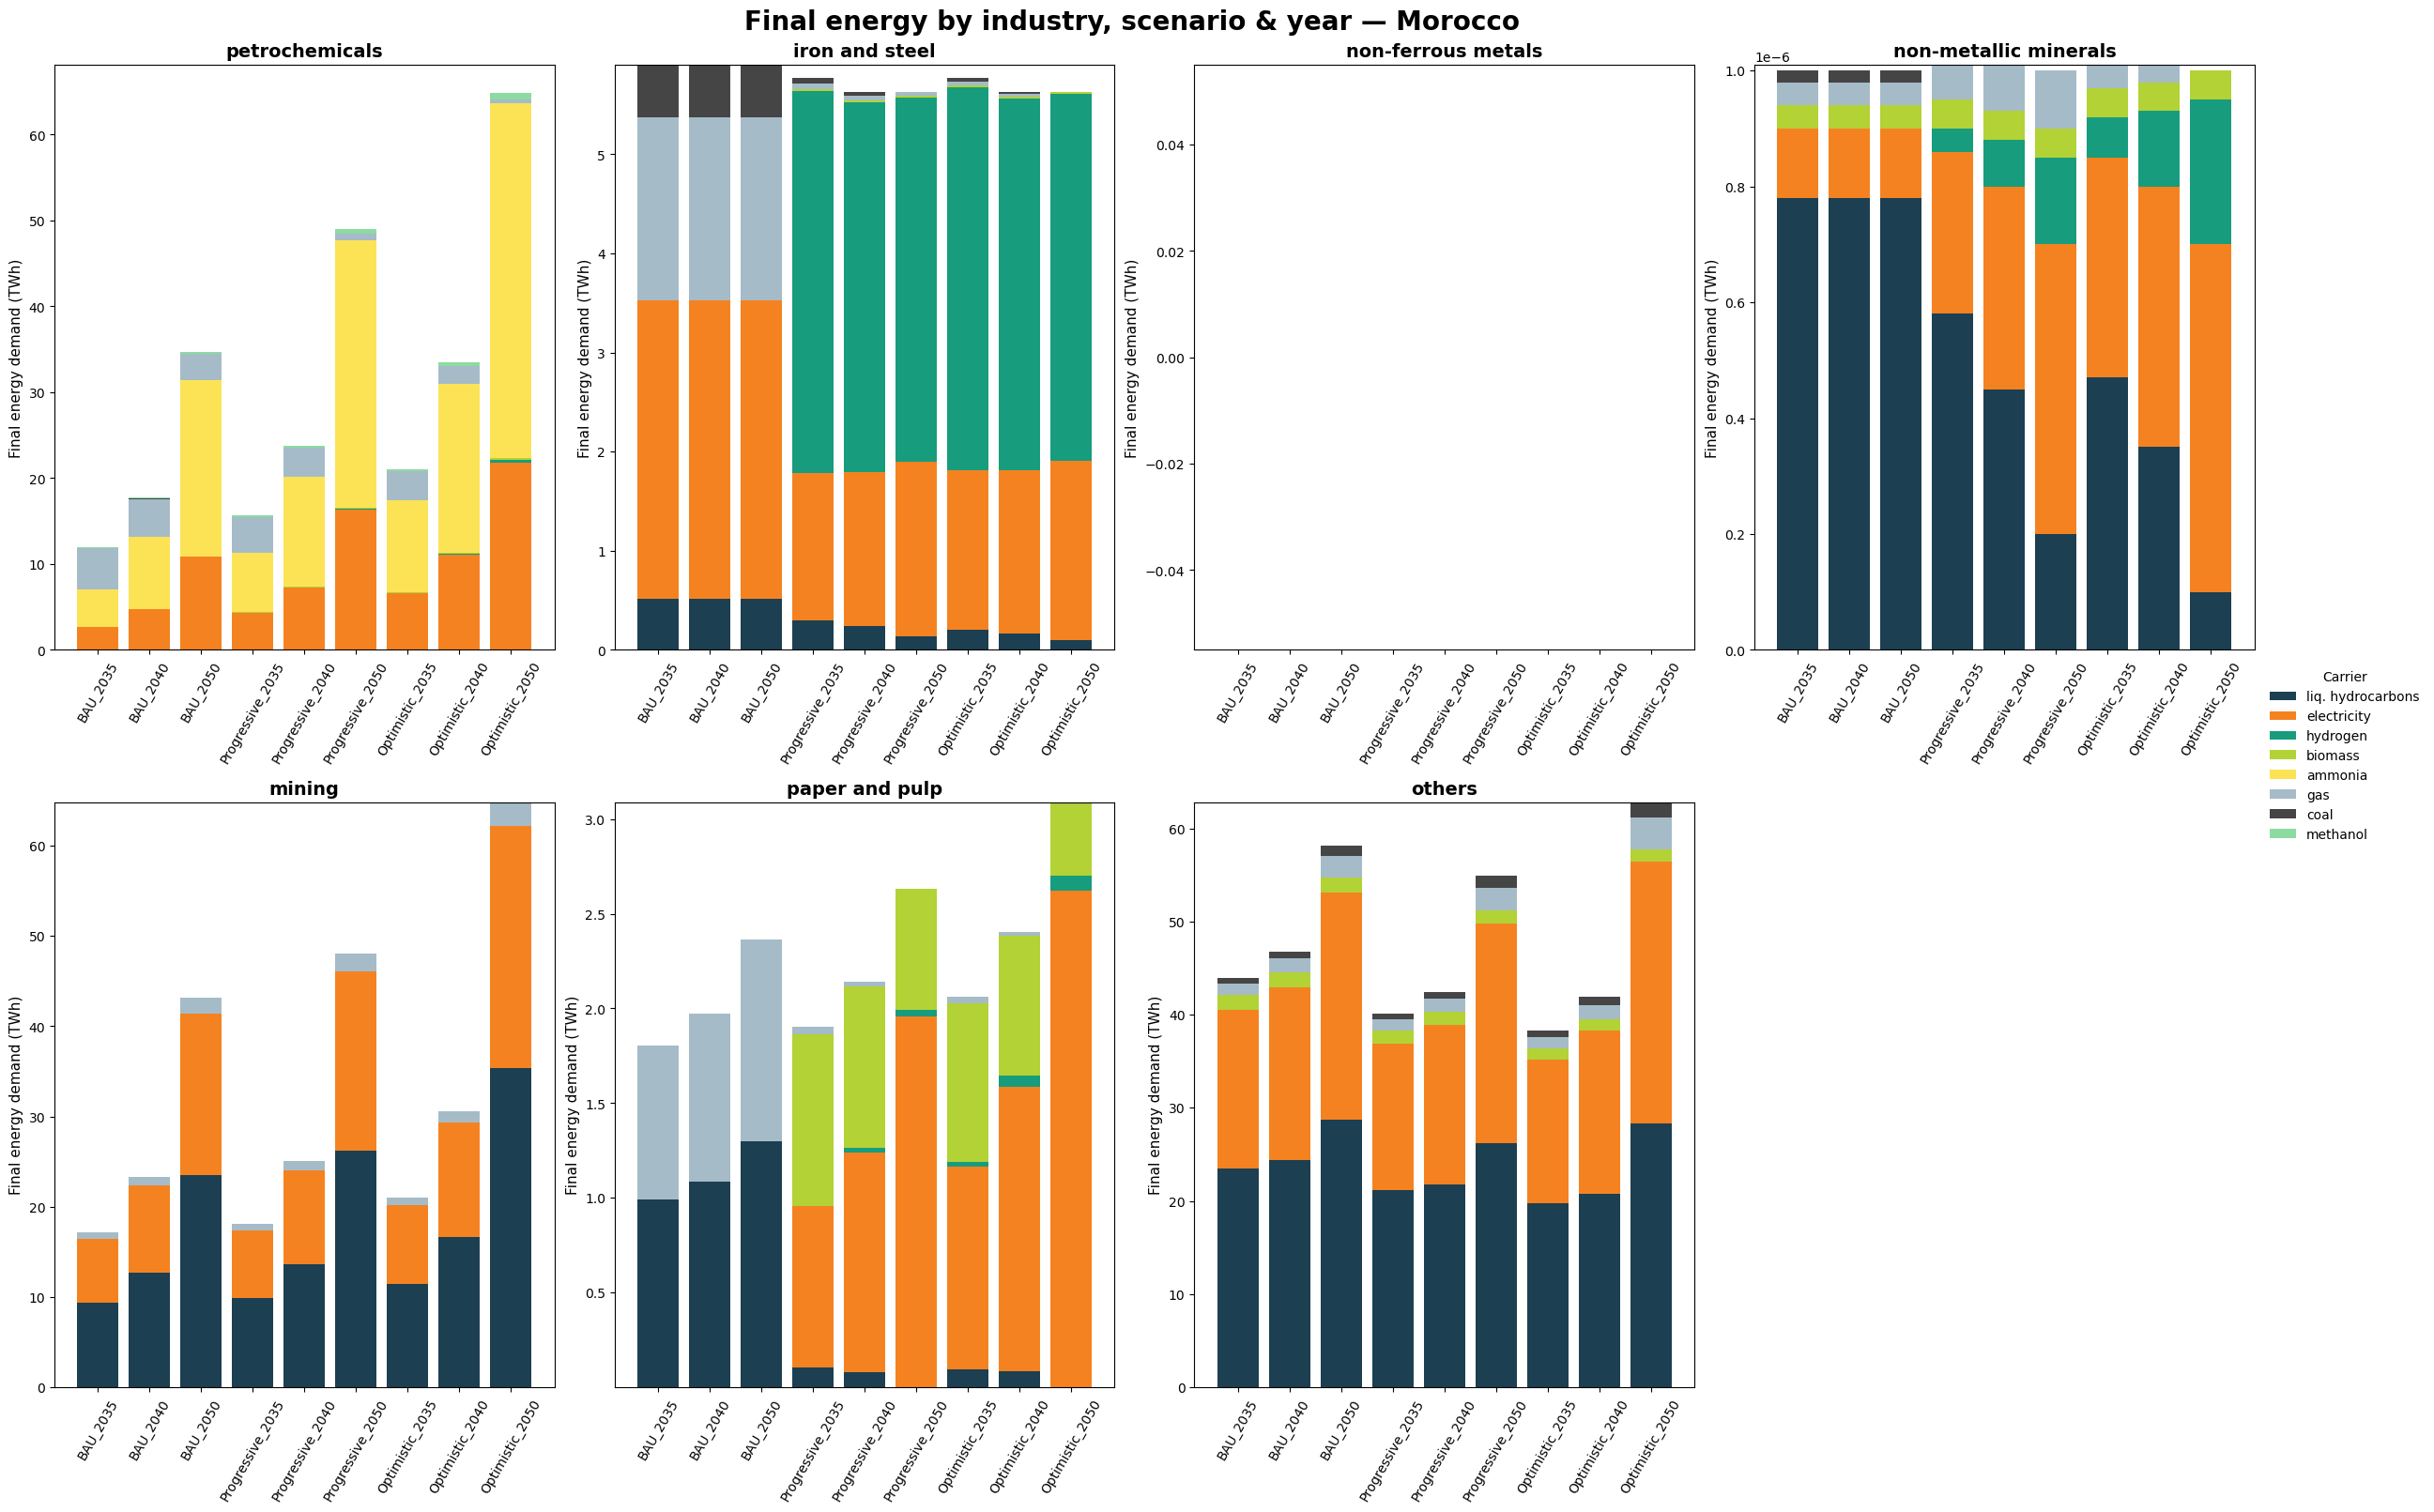

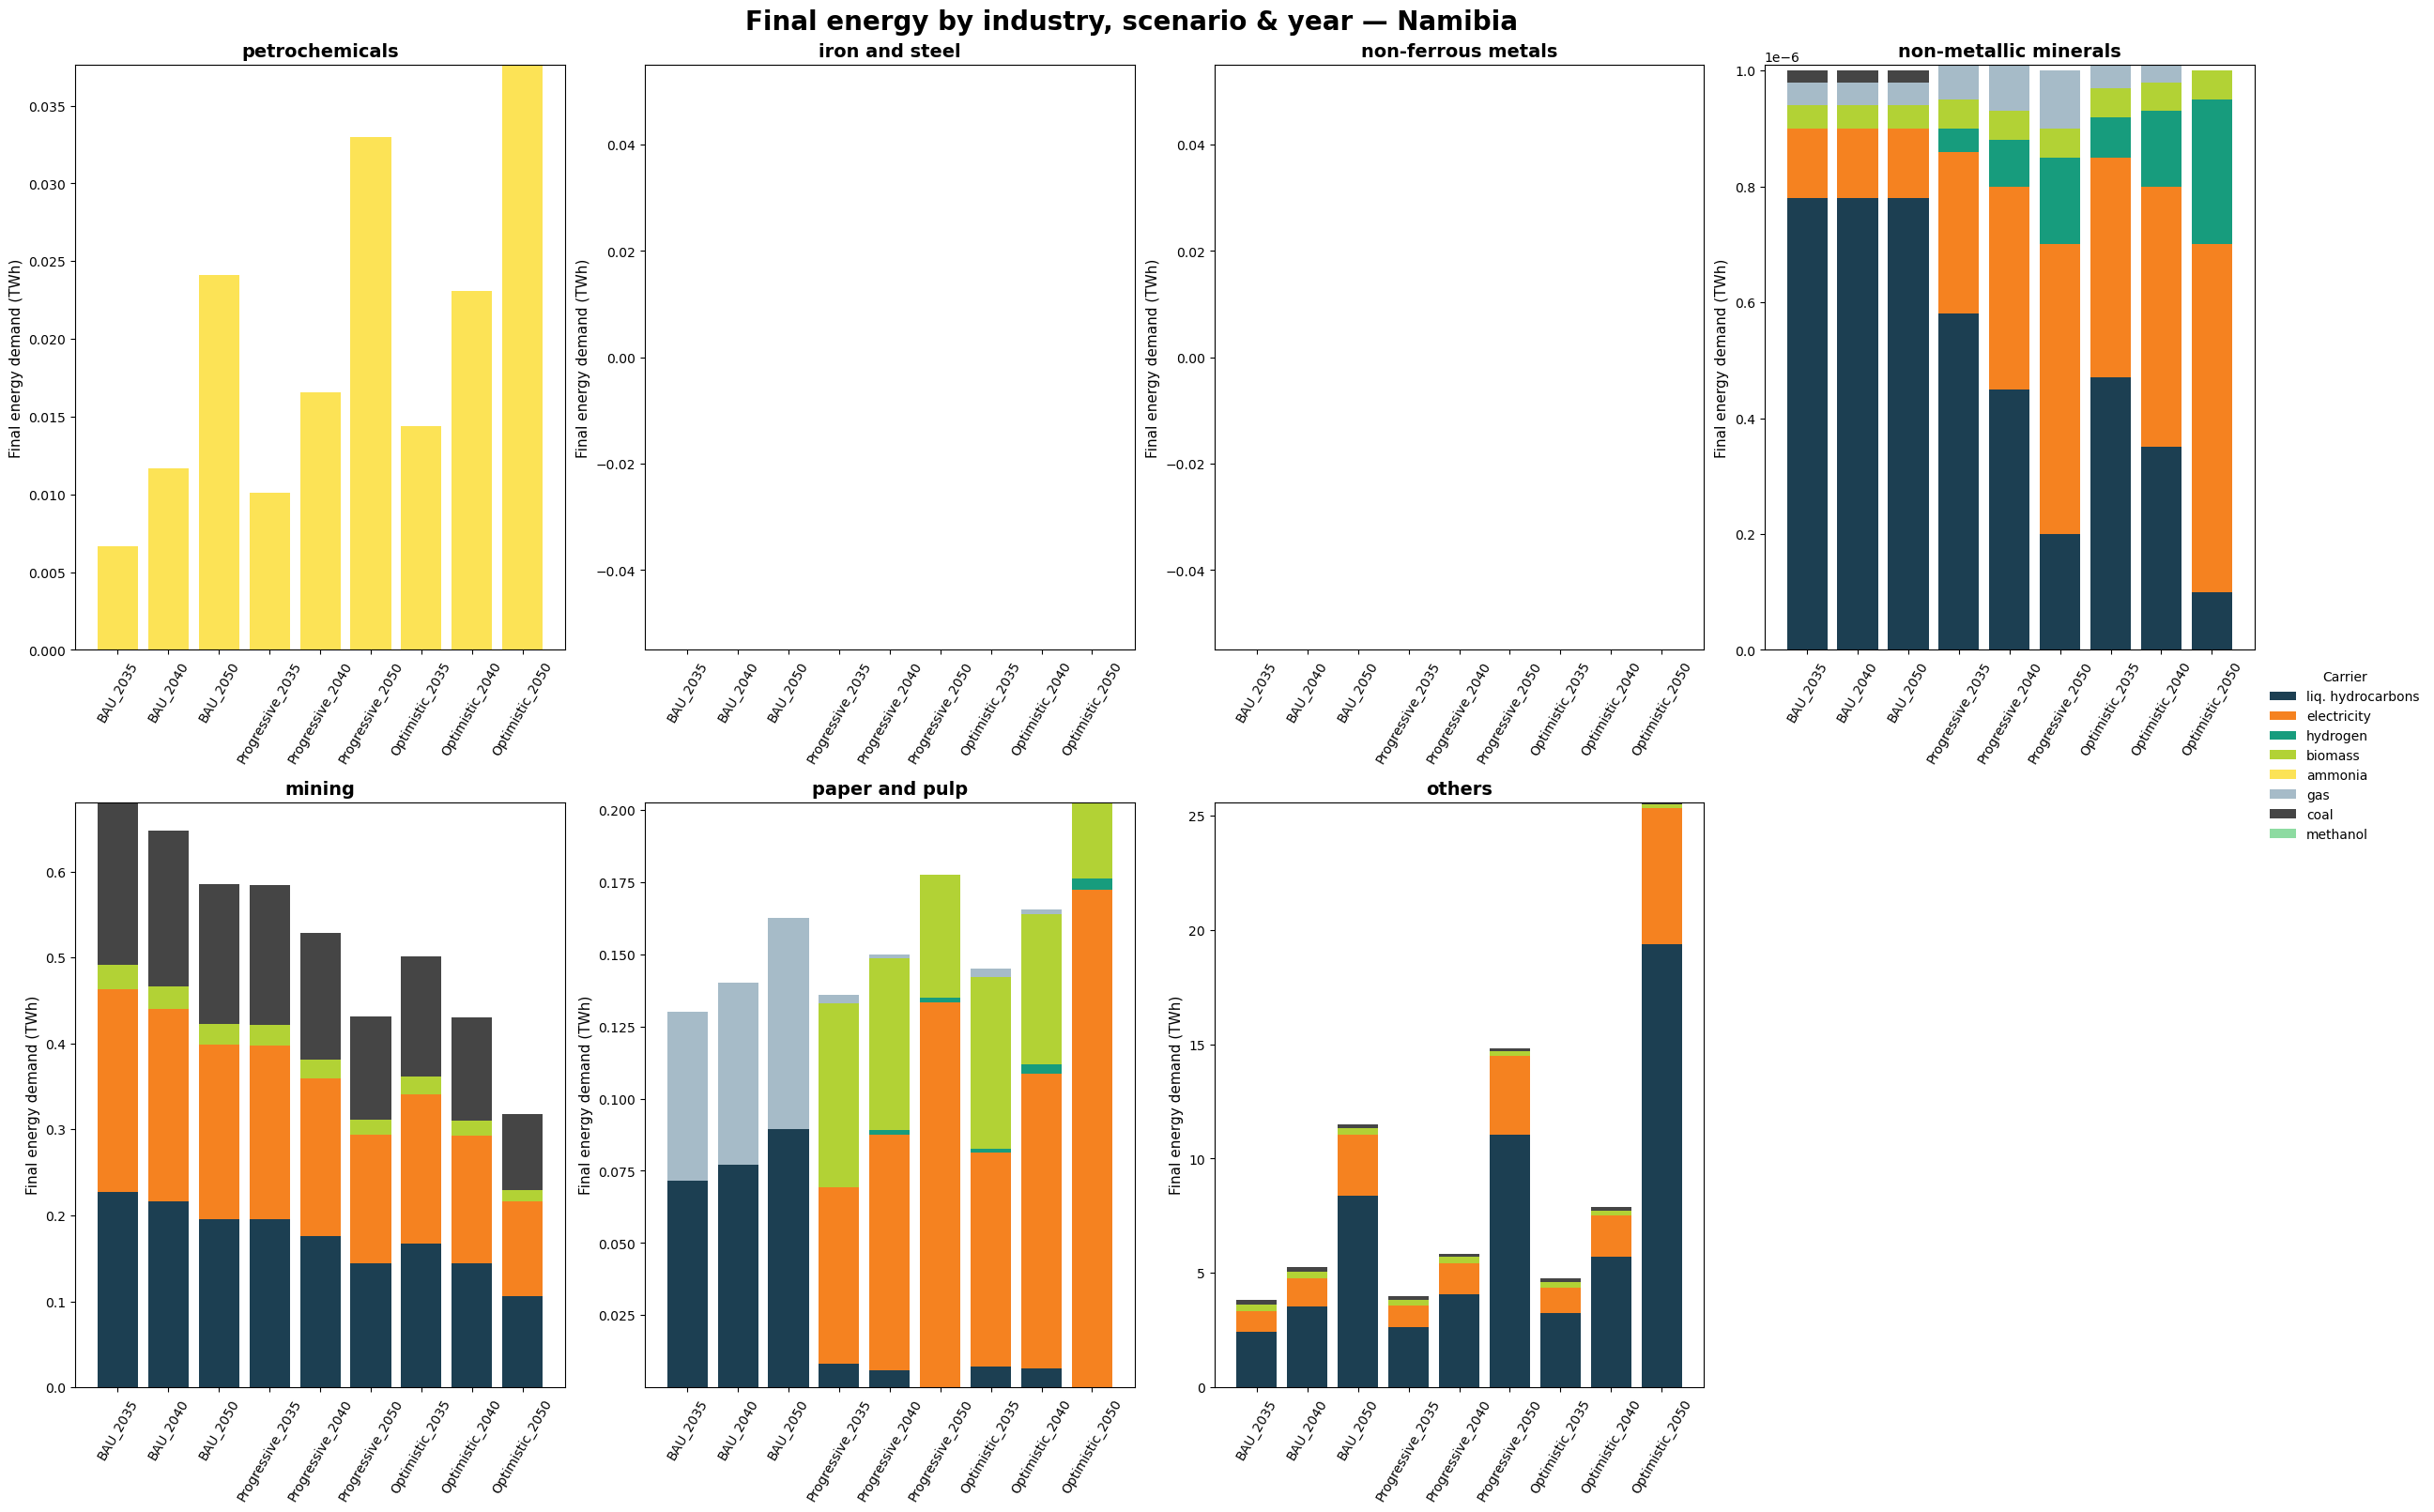

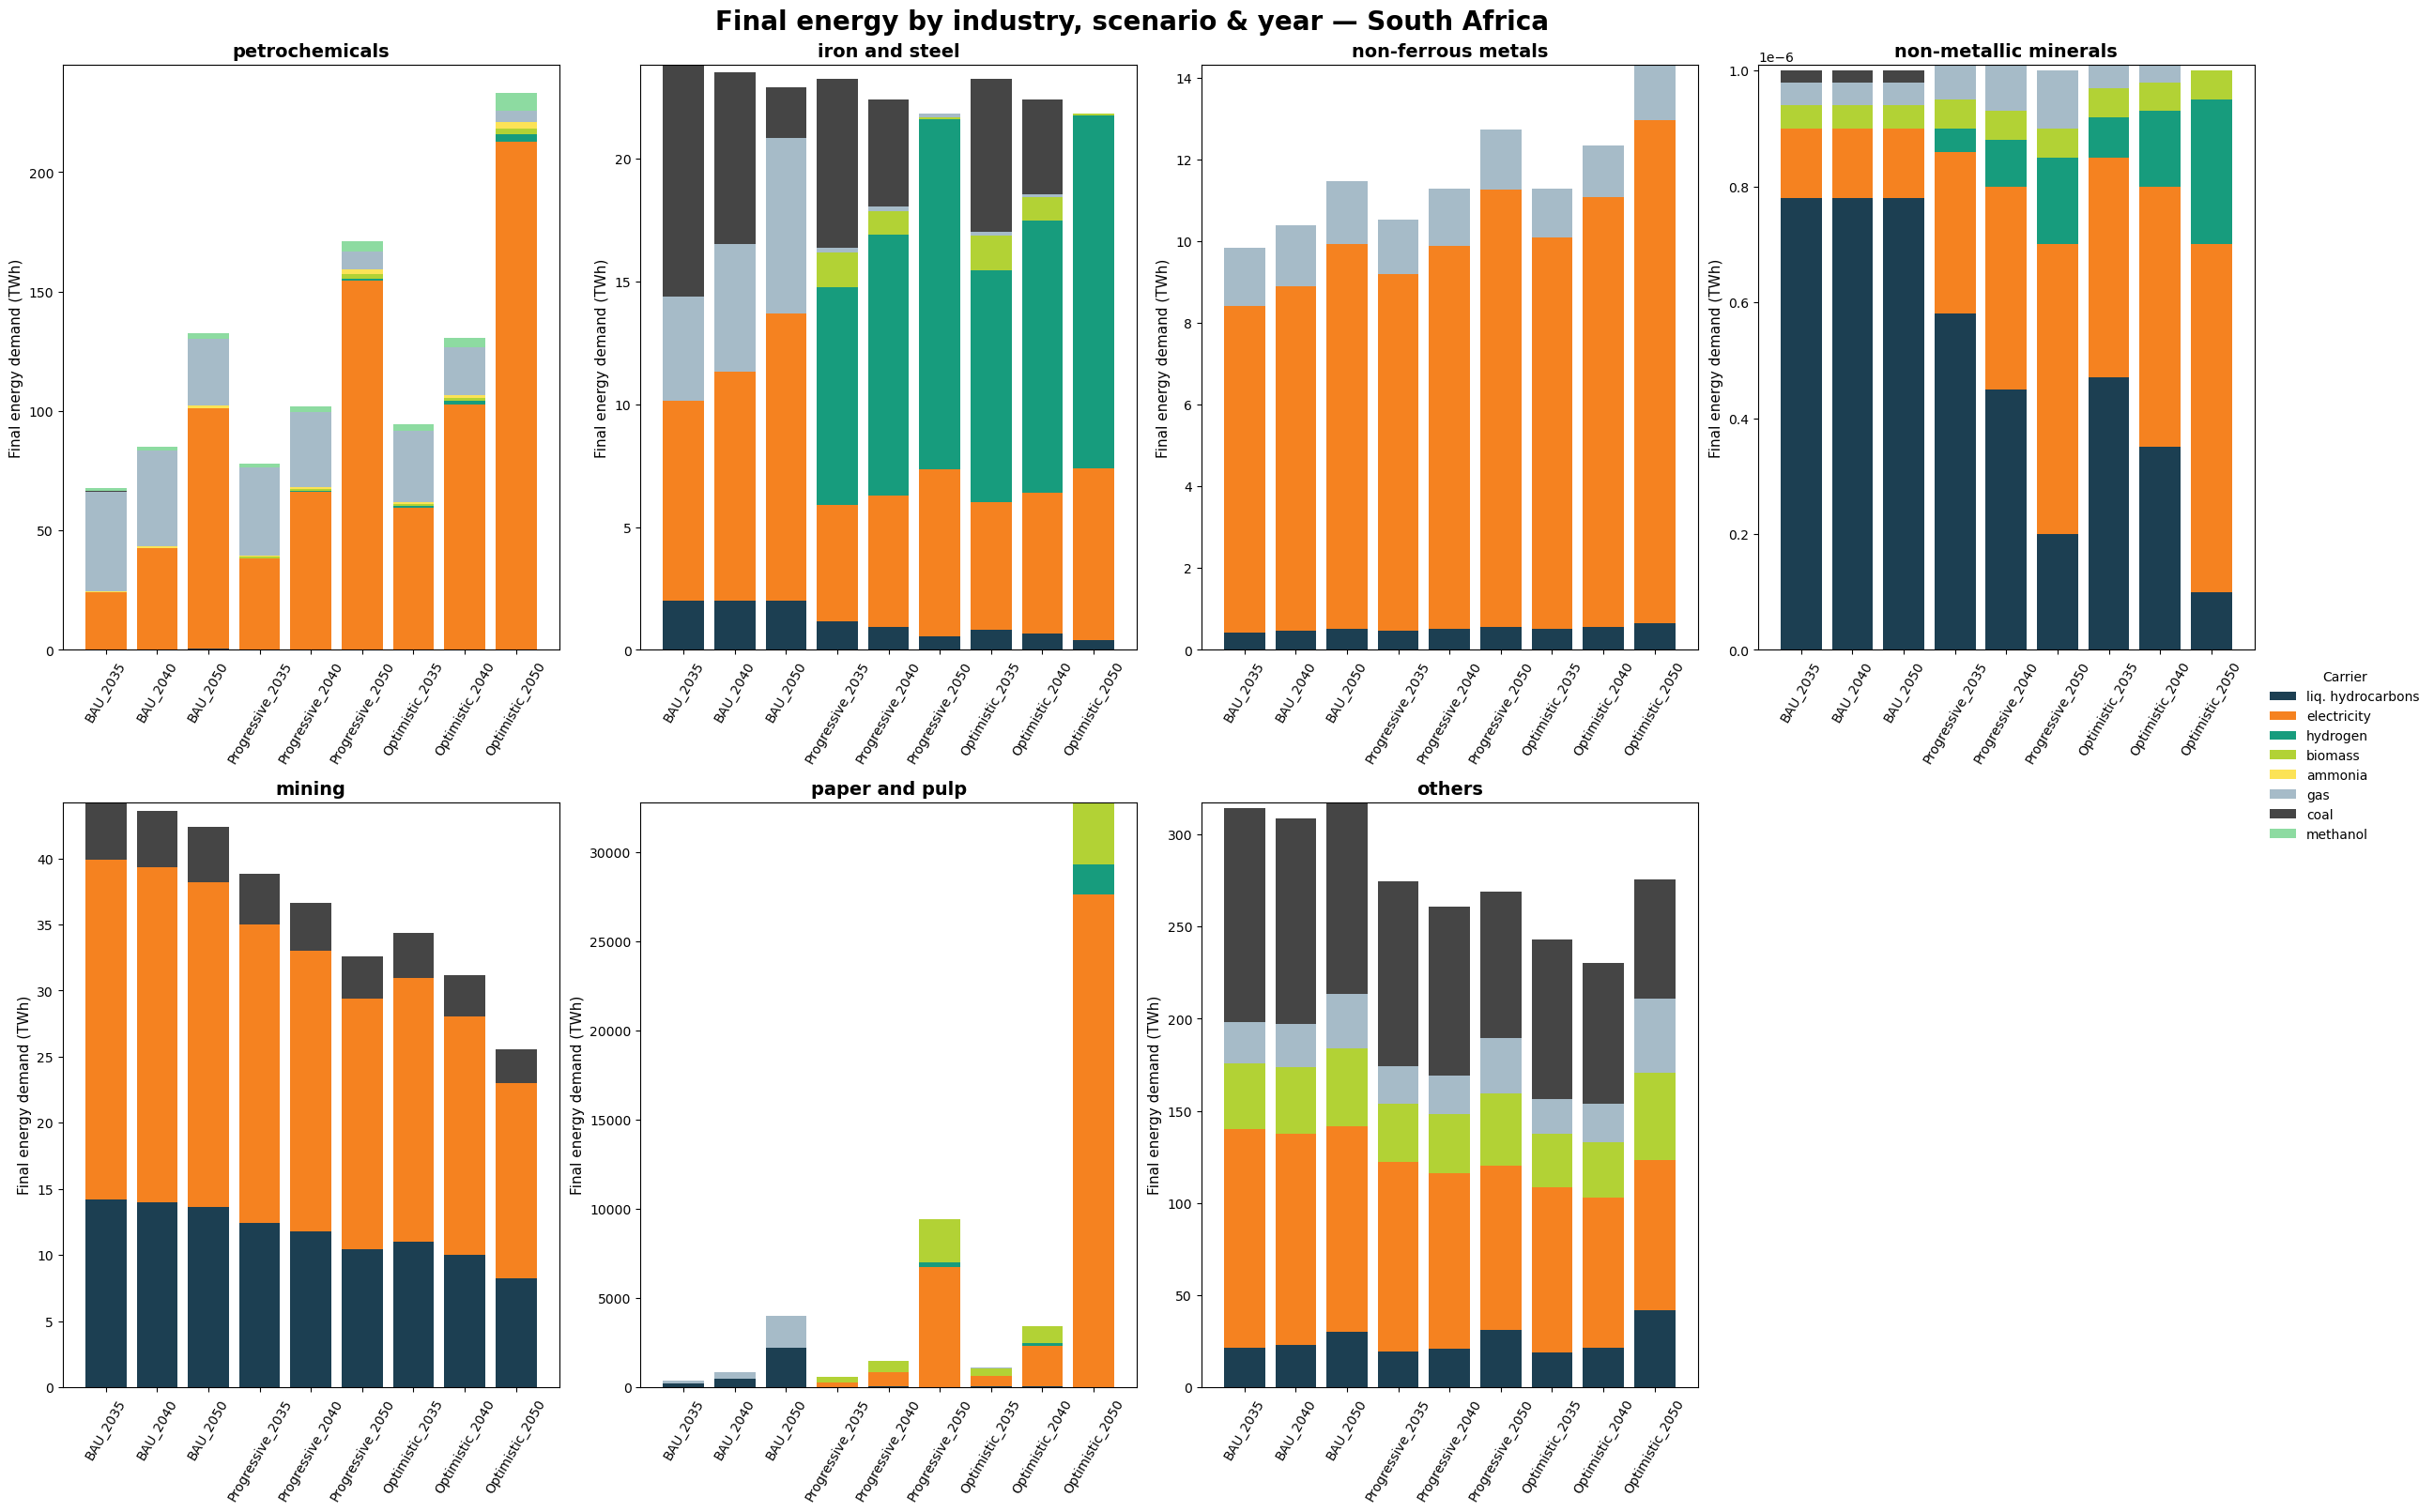

In [24]:
industry_colors = {
    'chemical and petrochemical': '#1c3f52',
    'iron and steel': '#b2d235',
    'non-ferrous metals': '#a6bbc8',
    'non-metallic minerals': '#008598',
    'mining and quarrying': '#e377c2',
    'paper pulp and print': '#228b22',
    'all_others': '#FCD80E',
}
industry_carrier_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
    'gas': '#a6bbc8',
    'coal': '#454545',
    'methanol': '#8ddba1',
}
facet_name_map = {
    'chemical and petrochemical': 'petrochemicals',
    'iron and steel': 'iron and steel',
    'mining and quarrying': 'mining',
    'non-ferrous metals': 'non-ferrous metals',
    'non-metallic minerals': 'non-metallic minerals',
    'all_others': 'others',
    'paper pulp and print': 'paper and pulp',
}

# Support both ISO-2 input and full names in labels/filters
country_dic = {
    "MA": "Morocco",
    "EG": "Egypt",
    "ZA": "South Africa",
    "NA": "Namibia",
    "Morocco": "Morocco",
    "Egypt": "Egypt",
    "South Africa": "South Africa",
    "Namibia": "Namibia",
}
country_code_to_name = {"MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia"}
industry_order = list(industry_colors.keys())
carrier_order  = list(industry_carrier_colors.keys())

# Build ordered scenario_year axis labels from the actual data
_scenario_base = ["Historic", "BAU", "Progressive", "Optimistic"]
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in _scenario_base
    for yr in sorted(df_long_agg["year"].unique())
    if f"{sc}_{yr}" in df_long_agg["scenario_year"].values
]

# Layout config — matches the single-country chart for consistent readability
PANEL_WIDTH = 6
ROW_HEIGHT  = 8
NCOLS       = 4

for cty, d in df_long_agg.groupby("country"):
    full_name = country_dic.get(cty, cty)
    n_industries = len(industry_order)
    nrows = int(np.ceil(n_industries / NCOLS))

    fig, axs = plt.subplots(nrows, NCOLS,
                            figsize=(PANEL_WIDTH * NCOLS, ROW_HEIGHT * nrows),
                            constrained_layout=True)
    axs_flat = np.array(axs).flatten()

    for i, industry in enumerate(industry_order):
        ax = axs_flat[i]
        d_ind = d[d["industry"] == industry].copy()
        d_ind["scenario_year"] = pd.Categorical(
            d_ind["scenario_year"], categories=scenario_year_order, ordered=True
        )
        pivot = d_ind.pivot_table(
            index="scenario_year", columns="carrier", values="value",
            aggfunc="sum", observed=False
        ).fillna(0)
        for carrier in carrier_order:
            if carrier not in pivot.columns:
                pivot[carrier] = 0
        pivot = pivot[carrier_order]
        bottom = np.zeros(len(pivot))
        for carrier in carrier_order:
            values = pivot[carrier].values
            ax.bar(pivot.index, values, bottom=bottom,
                   color=industry_carrier_colors[carrier], label=carrier)
            bottom += values
        ax.set_title(facet_name_map.get(industry, industry), fontsize=14, weight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Final energy demand (TWh)', fontsize=11)
        ax.tick_params(axis='x', rotation=60, labelsize=10)
        ax.tick_params(axis='y', labelsize=10)

    # Hide unused axes in the last row
    for ax in axs_flat[n_industries:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Final energy by industry, scenario & year — {full_name}",
        fontsize=20, weight='bold'
    )
    fig.legend(carrier_order, title="Carrier", loc='center left',
               bbox_to_anchor=(1.0, 0.5), fontsize='medium', frameon=False)
    plt.show()

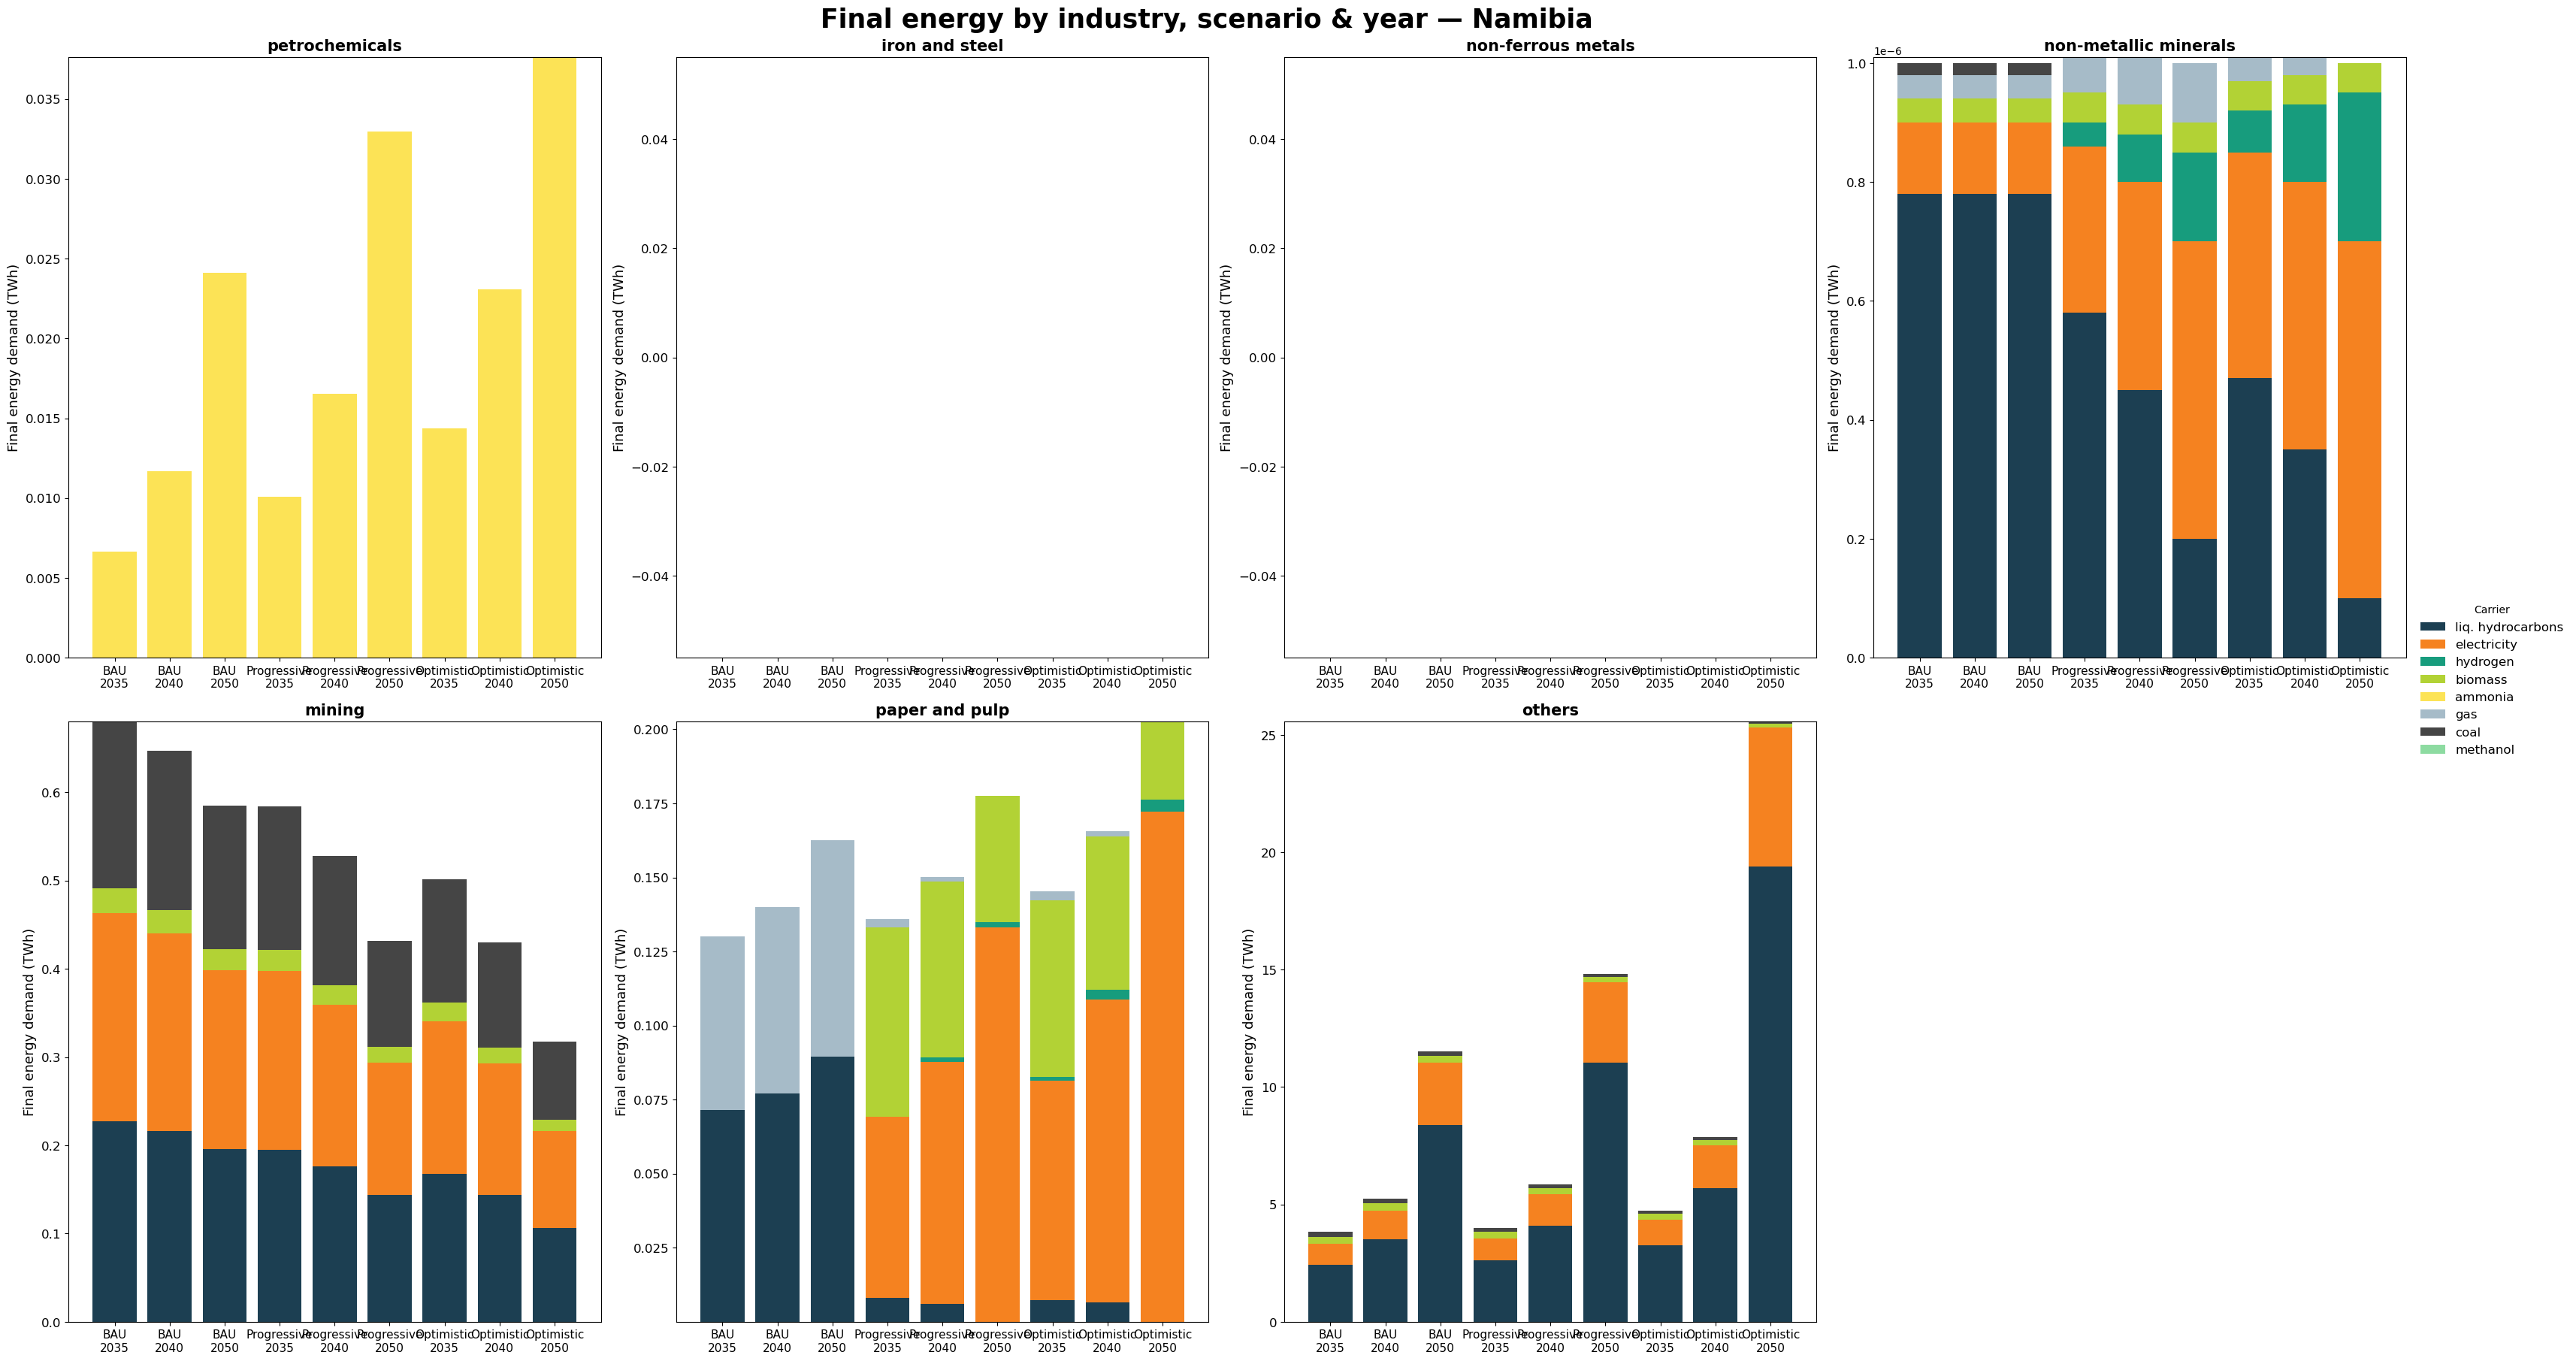

In [25]:
# -- SINGLE-COUNTRY FACETED CHART ------------------------------------------------
"""
Set CHART_COUNTRY to ISO-2 code ("MA", "EG", "ZA", "NA") or full country name.
"""
CHART_COUNTRY = "Namibia"

# Controls figure size: width per column (inches) and height per row (inches)
PANEL_WIDTH  = 8
ROW_HEIGHT   = 9
NCOLS        = 4   # 4 panels top row, remainder on bottom row

cty = country_code_to_name.get(CHART_COUNTRY, CHART_COUNTRY)
full_name = country_dic.get(cty, cty)
d = df_long_agg[df_long_agg["country"] == cty]
if d.empty:
    raise ValueError(
        f"No data for CHART_COUNTRY={CHART_COUNTRY}. "
        f"Available: {sorted(df_long_agg['country'].unique())}"
    )

n_industries = len(industry_order)
nrows = int(np.ceil(n_industries / NCOLS))

fig, axs = plt.subplots(nrows, NCOLS,
                        figsize=(PANEL_WIDTH * NCOLS, ROW_HEIGHT * nrows),
                        constrained_layout=True)
axs_flat = np.array(axs).flatten()

for i, industry in enumerate(industry_order):
    ax = axs_flat[i]
    d_ind = d[d["industry"] == industry].copy()
    d_ind["scenario_year"] = pd.Categorical(
        d_ind["scenario_year"], categories=scenario_year_order, ordered=True
    )
    pivot = d_ind.pivot_table(
        index="scenario_year", columns="carrier", values="value",
        aggfunc="sum", observed=False
    ).fillna(0)
    for carrier in carrier_order:
        if carrier not in pivot.columns:
            pivot[carrier] = 0
    pivot = pivot[carrier_order]
    # Split "Scenario_Year" -> "Scenario\nYear" for two-line x-axis labels
    pivot.index = [lbl.replace("_", "\n") for lbl in pivot.index]
    bottom = np.zeros(len(pivot))
    for carrier in carrier_order:
        values = pivot[carrier].values
        ax.bar(pivot.index, values, bottom=bottom,
               color=industry_carrier_colors[carrier], label=carrier)
        bottom += values
    ax.set_title(facet_name_map.get(industry, industry), fontsize=15, weight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Final energy demand (TWh)', fontsize=13)
    ax.tick_params(axis='x', rotation=0, labelsize=11)
    ax.tick_params(axis='y', labelsize=12)

# Hide unused axes in the last row
for ax in axs_flat[n_industries:]:
    ax.set_visible(False)

fig.suptitle(
    f"Final energy by industry, scenario & year — {full_name}",
    fontsize=25, weight='bold'
)
fig.legend(carrier_order, title="Carrier", loc='center left',
           bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
plt.show()

In [10]:
# NOTE: Egypt does not have mining as demand because there was no data available on that regard in any reliable source.

In [11]:
from IPython.display import display

# Pivot table: country × industry × scenario_year → carriers as columns
industry_type_table = df_long_agg.pivot_table(
    index=["country", "industry", "scenario_year"],
    columns="carrier",
    values="value",
    aggfunc="sum"
).reindex(columns=carrier_order).reset_index()

industry_type_table["country"] = industry_type_table["country"].map(
    lambda c: country_dic.get(c, c)
)

display(industry_type_table)


carrier,country,industry,scenario_year,liq. hydrocarbons,electricity,hydrogen,biomass,ammonia,gas,coal,methanol
0,Egypt,all_others,BAU_2035,9.038893e+01,87.306836,NaN,13.861328,0.0,1.165693e+02,20.342206,0.0
1,Egypt,all_others,BAU_2040,8.840758e+01,85.595340,NaN,13.624070,0.0,1.147209e+02,20.237403,0.0
2,Egypt,all_others,BAU_2050,8.480062e+01,82.492413,NaN,13.196356,0.0,1.114007e+02,20.068160,0.0
3,Egypt,all_others,Optimistic_2035,6.941254e+01,67.281998,0.000000,10.722333,0.0,9.034294e+01,16.019868,0.0
4,Egypt,all_others,Optimistic_2040,6.230800e+01,60.609478,0.000000,9.695300,0.0,8.184372e+01,14.740966,0.0
...,...,...,...,...,...,...,...,...,...,...,...
247,South Africa,paper pulp and print,Optimistic_2040,7.696872e+01,2246.402152,135.503790,979.122289,0.0,8.047632e+00,0.000000,0.0
248,South Africa,paper pulp and print,Optimistic_2050,5.000000e-08,27625.457464,1655.173888,3513.814188,0.0,0.000000e+00,0.000000,0.0
249,South Africa,paper pulp and print,Progressive_2035,2.338105e+01,251.133725,3.545069,286.697112,0.0,1.783805e+01,0.000000,0.0
250,South Africa,paper pulp and print,Progressive_2040,4.208041e+01,781.947322,28.750737,611.524578,0.0,3.155545e+01,0.000000,0.0


In [12]:
# TODO WHY THERE IS NO AMMONIA!!!!???

In [13]:
# Colour and order configuration — shared by the aggregate charts below
industry_carrier_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
    'gas': '#a6bbc8',
    'coal': '#454545',
    'methanol': '#8ddba1',
}
carrier_order       = list(industry_carrier_colors.keys())
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in ["Historic", "BAU", "Progressive", "Optimistic"]
    for yr in sorted(df_long_agg["year"].unique())
    if f"{sc}_{yr}" in df_long_agg["scenario_year"].values
]
country_dic = {"MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia"}


In [14]:
df_long_agg.carrier.unique()

array(['ammonia', 'biomass', 'coal', 'electricity', 'gas', 'methanol',
       'liq. hydrocarbons', 'steel', 'hydrogen'], dtype=object)

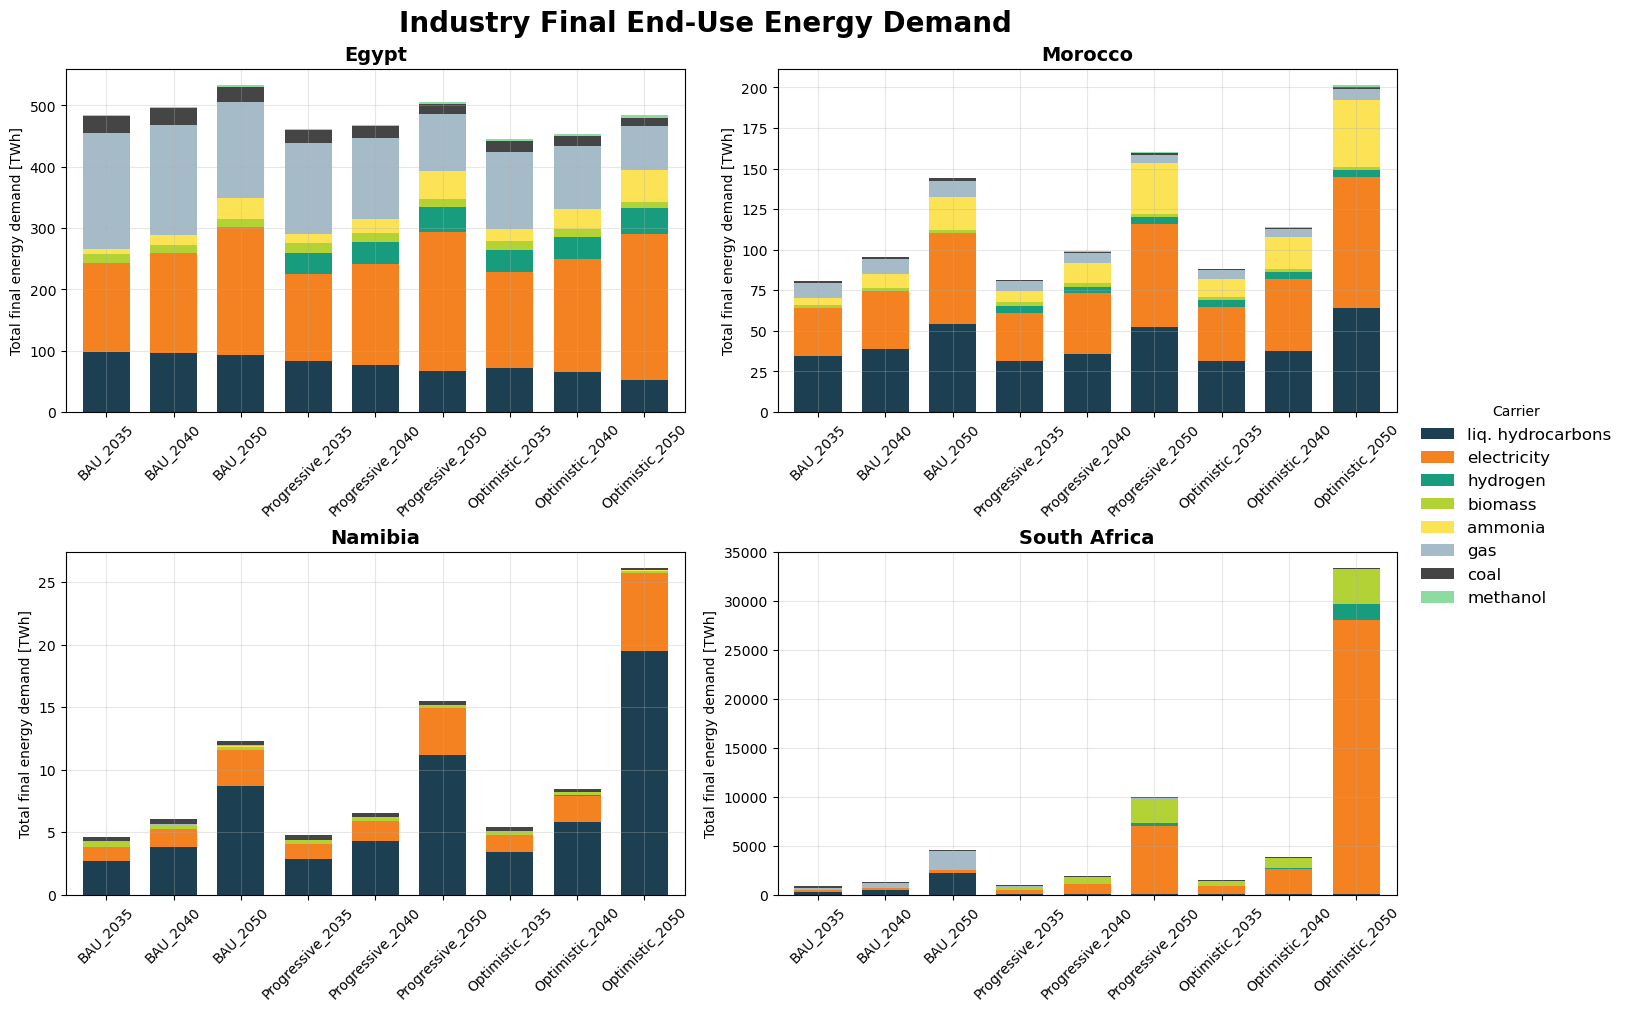

In [15]:
def plot_industry_bar_agg(df_agg, country_code, ax, country_dic=country_dic):
    """Stacked bar chart: total industry energy by scenario_year, coloured by carrier."""
    df_country = (
        df_agg[df_agg["country"] == country_code]
        .groupby(["scenario_year", "carrier"], as_index=False)["value"]
        .sum()
    )
    df_country["scenario_year"] = pd.Categorical(
        df_country["scenario_year"], categories=scenario_year_order, ordered=True
    )
    df_pivot = (
        df_country.pivot(index="scenario_year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Total final energy demand [TWh]")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

countries = sorted(df_long_agg["country"].unique())
ncols = min(2, len(countries))
nrows = int(np.ceil(len(countries) / ncols))

fig, axs = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), constrained_layout=True)
axs_flat = np.array(axs).flatten()

for idx, cty in enumerate(countries):
    plot_industry_bar_agg(df_long_agg, cty, axs_flat[idx])

# Hide unused axes
for ax in axs_flat[len(countries):]:
    ax.set_visible(False)

fig.suptitle("Industry Final End-Use Energy Demand", fontsize=20, weight="bold")
handles, labels = axs_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="large", frameon=False)
plt.show()


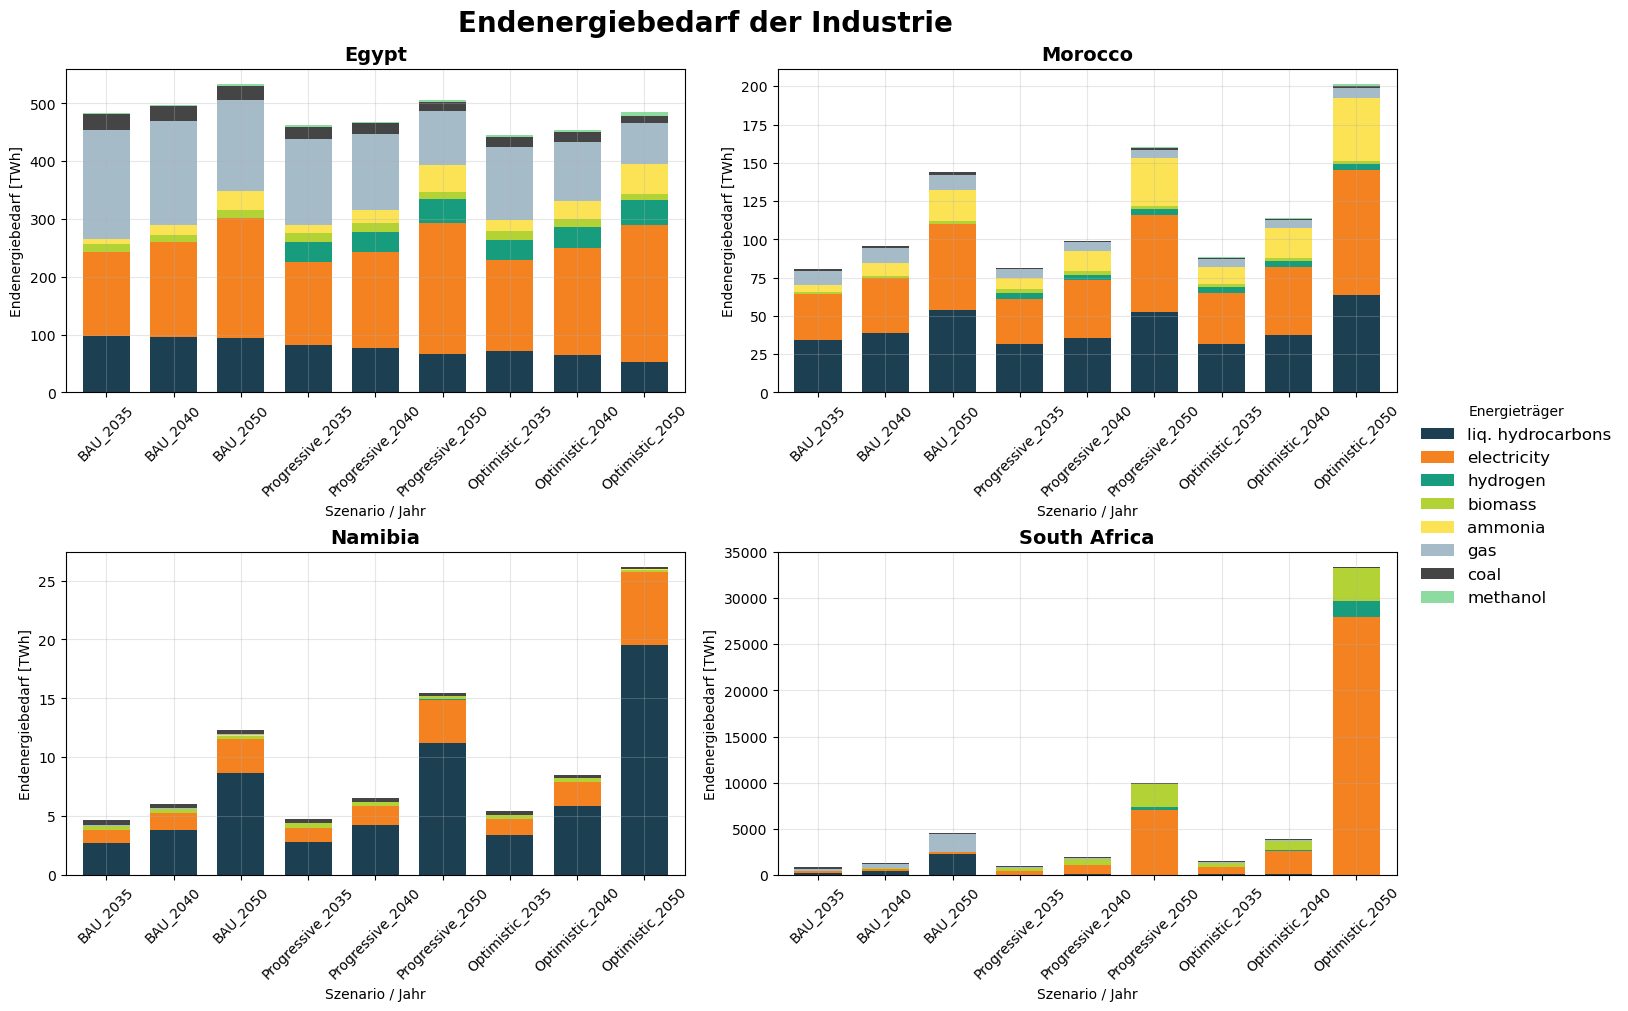

In [16]:
country_dic_de = {"MA": "Marokko", "EG": "Ägypten", "ZA": "Südafrika", "NA": "Namibia"}

def plot_industry_bar_agg_de(df_agg, country_code, ax):
    """German-labelled stacked bar chart: total industry energy by scenario_year."""
    df_country = (
        df_agg[df_agg["country"] == country_code]
        .groupby(["scenario_year", "carrier"], as_index=False)["value"]
        .sum()
    )
    df_country["scenario_year"] = pd.Categorical(
        df_country["scenario_year"], categories=scenario_year_order, ordered=True
    )
    df_pivot = (
        df_country.pivot(index="scenario_year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic_de.get(country_code, country_code), fontsize=14, weight="bold")
    ax.set_xlabel("Szenario / Jahr")
    ax.set_ylabel("Endenergiebedarf [TWh]")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

countries = sorted(df_long_agg["country"].unique())
ncols = min(2, len(countries))
nrows = int(np.ceil(len(countries) / ncols))

fig, axs = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), constrained_layout=True)
axs_flat = np.array(axs).flatten()

for idx, cty in enumerate(countries):
    plot_industry_bar_agg_de(df_long_agg, cty, axs_flat[idx])

for ax in axs_flat[len(countries):]:
    ax.set_visible(False)

fig.suptitle("Endenergiebedarf der Industrie", fontsize=20, weight="bold")
handles, labels = axs_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Energieträger", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="large", frameon=False)
plt.show()


In [17]:
# ── ADDITIONAL FILTERED ANALYSIS ──────────────────────────────────────────────
# Set country, scenario(s), and years for the charts below.
# These are independent from the global SELECTED_* filters above.
FOCUS_COUNTRY   = "NA"                                    # single ISO-2 code
FOCUS_SCENARIOS = ["BAU", "Progressive", "Optimistic"]   # subset or all
FOCUS_YEARS     = None                                    # None = all available years


In [18]:
# Chart A — selected country: total energy evolution over years, one subplot per scenario
# X = year, stacked bars by carrier

# Use the full (unfiltered) df_long before global SELECTED_* reduce its scope
df_focus = df.copy()
df_focus["carrier"] = df_focus["carrier"].replace("oil", "liq. hydrocarbons")
df_focus = df_focus[~df_focus["carrier"].isin(["heat", "process emissions"])]
df_focus = df_focus.fillna(0)

df_focus = df_focus[df_focus["country"] == FOCUS_COUNTRY]
if FOCUS_SCENARIOS:
    df_focus = df_focus[df_focus["scenario"].isin(FOCUS_SCENARIOS)]
if FOCUS_YEARS:
    df_focus = df_focus[df_focus["year"].isin(FOCUS_YEARS)]

# Melt and compute total per year × carrier × scenario
df_focus_long = df_focus.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry", value_name="value"
)
df_focus_total = (
    df_focus_long.groupby(["scenario", "year", "carrier"], as_index=False)["value"]
    .sum()
)
df_focus_total["value"] /= 1_000_000  # MWh → TWh

scenarios_present = [s for s in ["Historic", "BAU", "Progressive", "Optimistic"]
                     if s in df_focus_total["scenario"].unique()]

fig, axs = plt.subplots(1, len(scenarios_present),
                        figsize=(5 * len(scenarios_present), 5),
                        sharey=True, constrained_layout=True)
if len(scenarios_present) == 1:
    axs = [axs]

for ax, sc in zip(axs, scenarios_present):
    d_sc = df_focus_total[df_focus_total["scenario"] == sc]
    pivot = (
        d_sc.pivot(index="year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in pivot.columns]
    pivot.plot.bar(ax=ax, color=colors, width=0.7, stacked=True, legend=False)
    ax.set_title(sc, fontsize=12, weight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Total final energy [TWh]" if sc == scenarios_present[0] else "")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=0)

full_name = country_dic.get(FOCUS_COUNTRY, FOCUS_COUNTRY)
fig.suptitle(f"{full_name} — Industry energy by carrier & scenario", fontsize=14, weight="bold")
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="small", frameon=False)
plt.show()


ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x500 with 0 Axes>

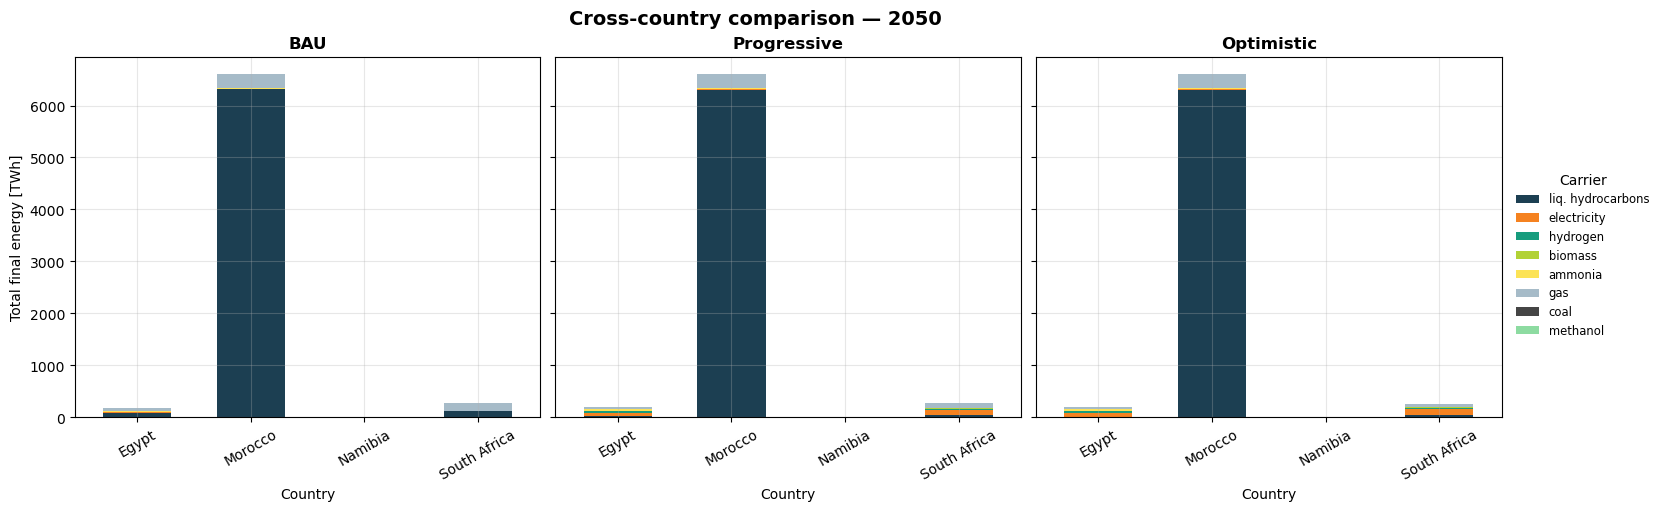

In [ ]:
# Chart B — cross-country comparison for a specific year and scenario
# Uses FOCUS_SCENARIOS[0] and the last year in FOCUS_YEARS (or latest available)

_compare_scenarios = FOCUS_SCENARIOS if FOCUS_SCENARIOS else ["BAU"]
_compare_year = (FOCUS_YEARS[-1] if FOCUS_YEARS
                 else int(df_focus_long["year"].max()) if len(df_focus_long) > 0
                 else 2050)

df_compare = df.copy()
df_compare["carrier"] = df_compare["carrier"].replace("oil", "liq. hydrocarbons")
df_compare = df_compare[~df_compare["carrier"].isin(["heat", "process emissions"])]
df_compare = df_compare.fillna(0)
df_compare = df_compare[
    (df_compare["scenario"].isin(_compare_scenarios)) &
    (df_compare["year"] == _compare_year)
]

df_compare_long = df_compare.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry", value_name="value"
)
df_compare_total = (
    df_compare_long.groupby(["country", "scenario", "carrier"], as_index=False)["value"]
    .sum()
)
df_compare_total["value"] /= 1_000_000  # MWh → TWh
df_compare_total["country_name"] = df_compare_total["country"].map(
    lambda c: country_dic.get(c, c)
)

scenarios_to_plot = [s for s in ["Historic", "BAU", "Progressive", "Optimistic"]
                     if s in df_compare_total["scenario"].unique()]

fig, axs = plt.subplots(1, len(scenarios_to_plot),
                        figsize=(5 * len(scenarios_to_plot), 5),
                        sharey=True, constrained_layout=True)
if len(scenarios_to_plot) == 1:
    axs = [axs]

for ax, sc in zip(axs, scenarios_to_plot):
    d_sc = df_compare_total[df_compare_total["scenario"] == sc]
    pivot = (
        d_sc.pivot(index="country_name", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in pivot.columns]
    pivot.plot.bar(ax=ax, color=colors, width=0.6, stacked=True, legend=False)
    ax.set_title(sc, fontsize=12, weight="bold")
    ax.set_xlabel("Country")
    ax.set_ylabel("Total final energy [TWh]" if sc == scenarios_to_plot[0] else "")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(f"Cross-country comparison — {_compare_year}", fontsize=14, weight="bold")
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="small", frameon=False)
plt.show()
